### OVM Analysis (Task 1 and Task 2)
1. Self-Implementation with TraCI
2. The condition is the sensitivity of relaxation parameter that causes congestion
3. Hence more sensitive, but if relaxation is greater, then their would not be conjestion

### Parameters that were being changed
1. The jam_speed_mps to be uniform with our group members
2. Then to give a more uniform density sweep

### toml files
1. OVM_600, 1200, 4800

In [1]:
# Some libraries used
import tomllib
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#### Experiment 1: To see if different ring road length affects flow while keeping everything the same

In [2]:
ROOT = Path.cwd().resolve().parent

files = {
    600: "OVM_600.csv",
    1200: "OVM_1200.csv",
    4800: "OVM_4800.csv"
}

frames = []

for length, filename in files.items():
    path = ROOT / "results" / "ring" / filename

    df = pd.read_csv(path)
    df["ring_length_m"] = length
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

In [3]:
# Some inspection
for col in df_all.columns: print(col)
df_all.head(5)

validation = (
    df_all.groupby("ring_length_m")
    .agg(
        runs=("run_id", "count"),
        densities=("density_veh_km", "nunique"),
        seeds=("seed", "nunique"),
        valid_runs=("valid", "sum")
    )
)

run_id
scenario
model
variant
seed
density_veh_km
mean_speed_mps
flow_veh_h
congested_fraction
congested_fraction_var
valid
ring_vehicles
ring_length_m


In [4]:
# Assuming that they are valid
df_valid = df_all[df_all["valid"] == True].copy()

# Measurements of interest
metrics = [
    "mean_speed_mps",
    "flow_veh_h",
    "congested_fraction",
    "congested_fraction_var"
]

# Average across seeds for each density and ring length
summary = (df_valid.groupby(["ring_length_m", "density_veh_km"])
    .agg(
        **{
            f"{metric}_mean": (metric, "mean")
            for metric in metrics
        },
        **{
            f"{metric}_std": (metric, "std")
            for metric in metrics
        },
        n_seeds=("seed", "nunique")
    )
    .reset_index()
)

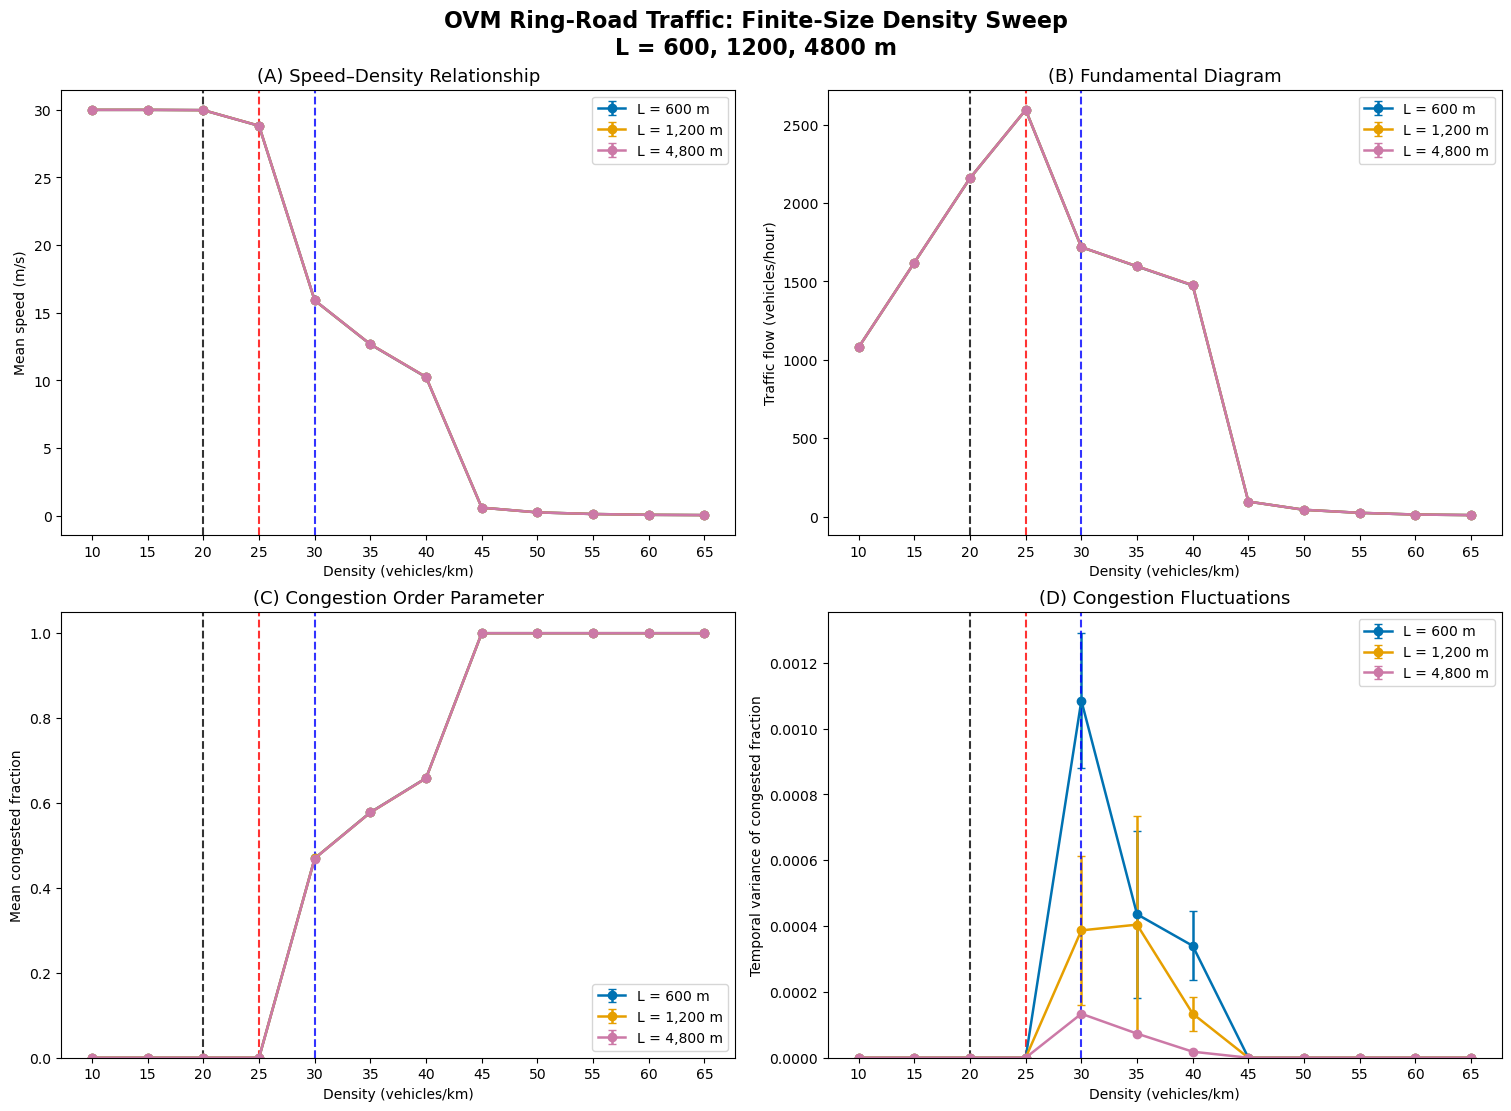

In [5]:
# To plot some figures for analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

plot_config = [
    {"metric": "mean_speed_mps", "title": "(A) Speed–Density Relationship", "ylabel": "Mean speed (m/s)"},
    {"metric": "flow_veh_h", "title": "(B) Fundamental Diagram", "ylabel": "Traffic flow (vehicles/hour)"},
    {"metric": "congested_fraction", "title": "(C) Congestion Order Parameter", "ylabel": "Mean congested fraction"},
    {"metric": "congested_fraction_var", "title": "(D) Congestion Fluctuations", "ylabel": "Temporal variance of congested fraction"}
]

ring_lengths = [600, 1200, 4800]

colors = {
    600:  "#0072B2",  # Blue
    1200: "#E69F00",  # Orange
    4800: "#CC79A7"   # Reddish purple
}

for ax, config in zip(axes.flat, plot_config):

    metric = config["metric"]

    for length in ring_lengths:

        subset = summary[summary["ring_length_m"] == length].sort_values("density_veh_km")

        ax.errorbar(subset["density_veh_km"], subset[f"{metric}_mean"], yerr=subset[f"{metric}_std"].fillna(0), marker="o", linewidth=1.8, markersize=6, capsize=3, color=colors[length], label=f"L = {length:,} m")

    # Vertical black dashed line at density = 20
    ax.axvline(x=20, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=25, color="red", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=30, color="blue", linestyle="--", linewidth=1.5, alpha=0.8)

    ax.set_title(config["title"], fontsize=13)
    ax.set_xlabel("Density (vehicles/km)")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks([10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65])
    ax.legend()

axes[1, 0].set_ylim(bottom=0)
axes[1, 0].set_ylim(top=1.05)
axes[1, 1].set_ylim(bottom=0)

fig.suptitle(
    "OVM Ring-Road Traffic: Finite-Size Density Sweep\n"
    "L = 600, 1200, 4800 m",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [6]:
# Then to plot the space-time diagram for all the densities
from traffic_project.measurements import iter_fcd

lengths = [600, 1200, 4800]
densities = [20, 25, 30, 40]

seed = 501

time_start = 600
time_end = 1800

spatial_bin = 20
temporal_bin = 10

In [7]:
def load_fcd_for_heatmap(length, n_vehicles, seed):

    run_id = f"ring_ovm_traci-dt0p2_L{length}_n{n_vehicles}_s{seed}"

    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    if not fcd_path.exists():
        raise FileNotFoundError(
            f"Missing FCD file:\n{fcd_path}\n"
            "Check the seed and run directory."
        )

    records = []

    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({
                "time": t,
                "position": x,
                "speed": vehicle["speed"]
            })

    if not records:
        raise ValueError(f"No trajectory observations in {fcd_path}")

    return pd.DataFrame(records)

In [8]:
def make_speed_matrix(df, length, spatial_bin=50, temporal_bin=10):

    n_space = int(np.ceil(length / spatial_bin))
    n_time = int(np.ceil((time_end - time_start) / temporal_bin))

    df = df.copy()

    df["space_idx"] = np.floor(
        df["position"] / spatial_bin
    ).astype(int).clip(0, n_space - 1)

    df["time_idx"] = np.floor(
        (df["time"] - time_start) / temporal_bin
    ).astype(int).clip(0, n_time - 1)

    matrix = (
        df.groupby(["time_idx", "space_idx"])["speed"]
        .mean()
        .unstack()
        .reindex(
            index=range(n_time),
            columns=range(n_space)
        )
    )

    return matrix.to_numpy()

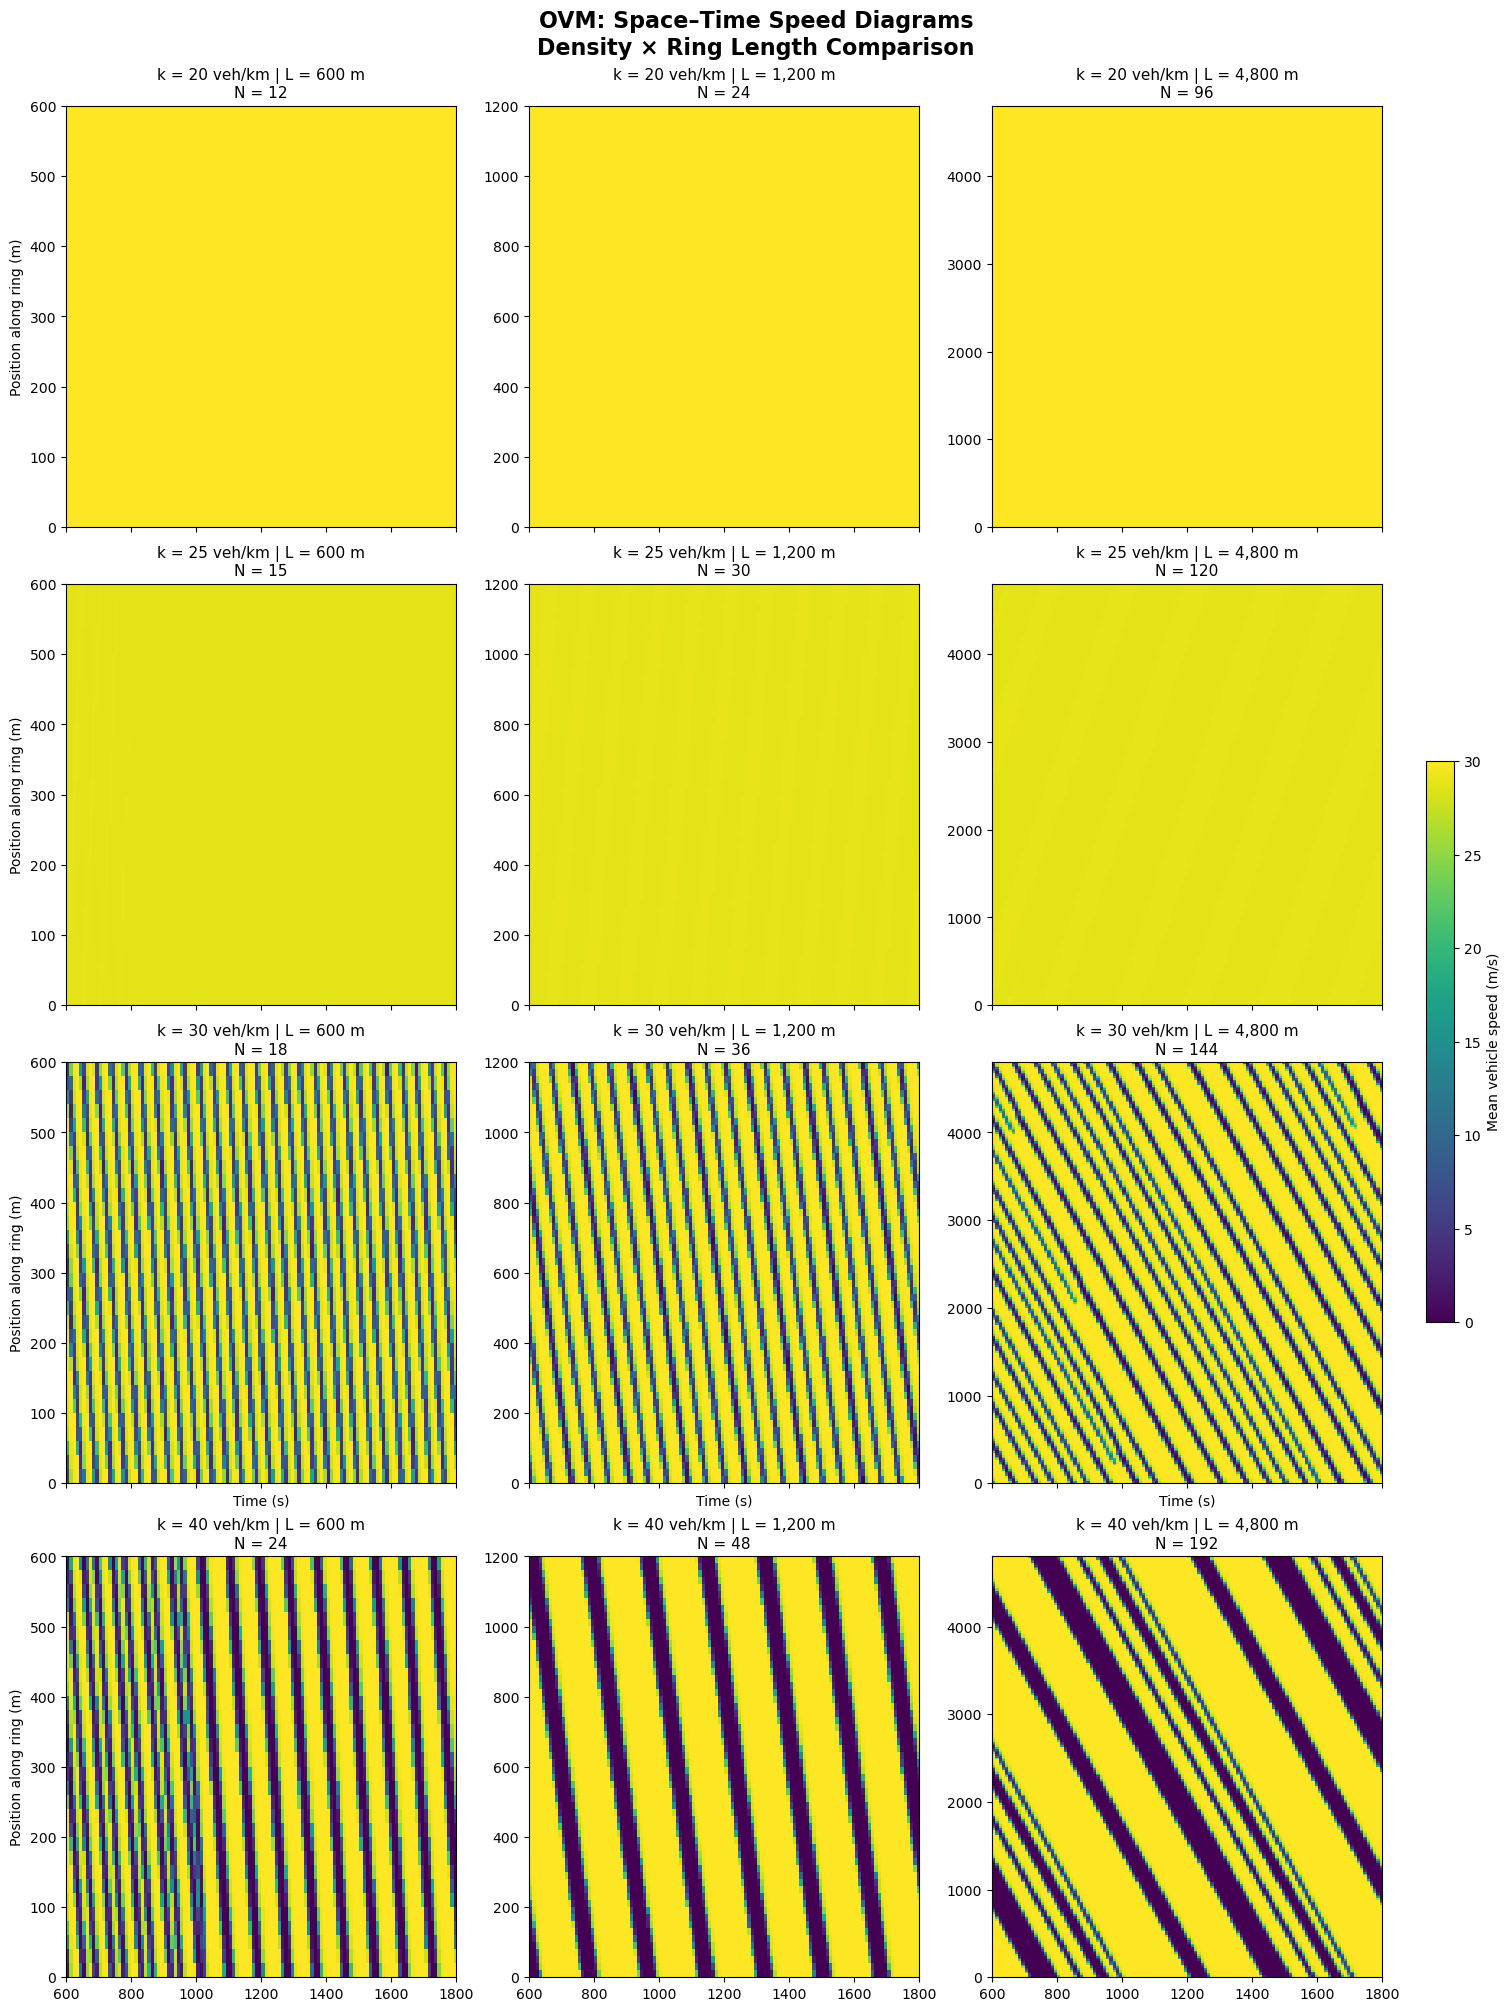

In [9]:
n_rows = len(densities)
n_cols = len(lengths)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 20), sharex=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, density in enumerate(densities):

    for col, length in enumerate(lengths):
        ax = axes[row, col]
        n_vehicles = int(density * length / 1000)
        df = load_fcd_for_heatmap(length, n_vehicles, seed)

        matrix = make_speed_matrix(
            df,
            length,
            spatial_bin=spatial_bin,
            temporal_bin=temporal_bin
        )

        im = ax.imshow(
            np.ma.masked_invalid(matrix.T),
            origin="lower",
            aspect="auto",
            extent=[time_start, time_end,0,length],
            cmap=cmap, vmin=0, vmax=30,
            interpolation="nearest"
        )

        ax.set_title(
            f"k = {density} veh/km | L = {length:,} m\n"
            f"N = {n_vehicles}",
            fontsize=11
        )

        if col == 0:
            ax.set_ylabel("Position along ring (m)")

        if row == 2:
            ax.set_xlabel("Time (s)")

fig.colorbar(im, ax=axes, label="Mean vehicle speed (m/s)",shrink=0.3, pad=0.02)
fig.suptitle("OVM: Space–Time Speed Diagrams\n" "Density × Ring Length Comparison", fontsize=16, fontweight="bold")
plt.show()

Why the longer road can support: Because the longer system can support more unstable spatial modes and multiple jam clusters.

### Experiment 2: To vary the relaxation parameters (Relaxation Rate Sweep)
1. a relaxation rate is the sensitivity to breaking
2. Hence is relaxation sensitivity is greater, there will be lesser stop-go-waves


In [10]:
alphas = [1.0, 2.0, 3.0, 4.0, 5.0]

ROOT = Path.cwd().resolve().parent

files = {
    1.0: "OVM_alpha_L1200_N36_a1.csv",
    2.0: "OVM_alpha_L1200_N36_a2.csv",
    3.0: "OVM_alpha_L1200_N36_a3.csv",
    4.0: "OVM_alpha_L1200_N36_a4.csv",
    5.0: "OVM_alpha_L1200_N36_a5.csv"
}

frames = []

for alpha, filename in files.items():

    path = ROOT / "results" / "ring" / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(path)

    # Assign relaxation rate
    df["alpha"] = alpha

    frames.append(df)

df_alphas = pd.concat(frames, ignore_index=True)

# Keep valid simulation runs
df_alphas = df_alphas[df_alphas["valid"] == True].copy()

In [11]:
metrics = ["mean_speed_mps", "congested_fraction", "congested_fraction_var"]

summary_ovm = (df_alphas.groupby("alpha").agg(**{f"{metric}_mean": (metric, "mean") for metric in metrics},
        **{f"{metric}_std": (metric, "std") for metric in metrics},
        n_seeds=("seed", "nunique")
    )
    .reset_index()
    .sort_values("alpha")
)

/var/folders/q3/33fyk8sd6dg0t8f3xpfmn0hr0000gn/T/ipykernel_88949/3268621791.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


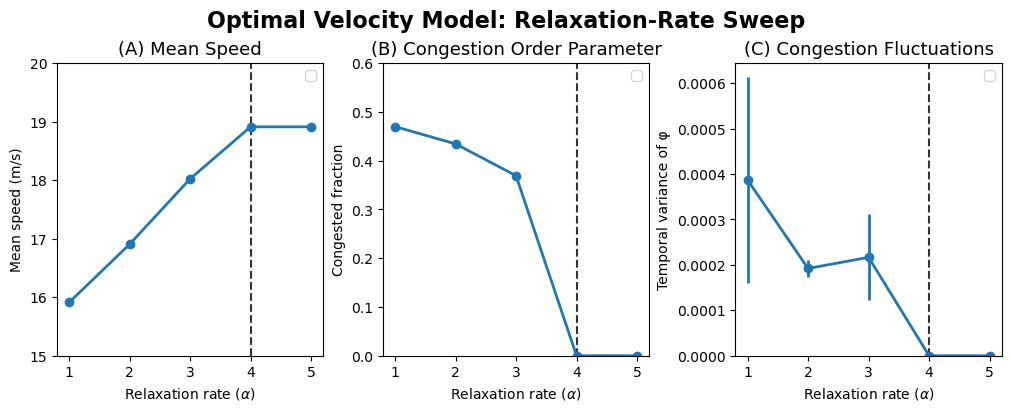

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4),sharex=True, constrained_layout=True)

plot_config = [
    {
        "metric": "mean_speed_mps",
        "title": "(A) Mean Speed",
        "ylabel": "Mean speed (m/s)",
        "color": "#0072B2"
    },
    {
        "metric": "congested_fraction",
        "title": "(B) Congestion Order Parameter",
        "ylabel": "Congested fraction",
        "color": "#009E73"
    },
    {
        "metric": "congested_fraction_var",
        "title": "(C) Congestion Fluctuations",
        "ylabel": "Temporal variance of φ",
        "color": "#CC79A7"
    }
]


for ax, config in zip(axes, plot_config):

    metric = config["metric"]

    ax.errorbar(
        summary_ovm["alpha"],
        summary_ovm[f"{metric}_mean"],
        yerr=summary_ovm[f"{metric}_std"].fillna(0),
        marker="o", linestyle="-", linewidth=2, markersize=6
    )

    ax.set_xlabel(r"Relaxation rate ($\alpha$)")
    ax.tick_params(labelbottom=True) 

    ax.set_title(config["title"], fontsize=13)
    ax.set_ylabel(config["ylabel"])
    ax.axvline(x=4, color="black", linestyle="--", linewidth=1.5, alpha=0.8)

    ax.legend()

# Axis limits
axes[0].set_ylim(15, 20)
axes[1].set_ylim(0, 0.6)
axes[2].set_ylim(bottom=0)

fig.suptitle("Optimal Velocity Model: Relaxation-Rate Sweep", fontsize=16, fontweight="bold")

plt.show()

In [13]:
def load_fcd_for_ovm(seed, alpha, length=1200, n_vehicles=36):
    
    run_id = (f"ring_ovm_traci-dt0p2-alpha-{alpha}_L1200_n36_s{seed}")
    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    records = []

    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({"time": t, "position": x, "speed": vehicle["speed"]})

    return pd.DataFrame(records)

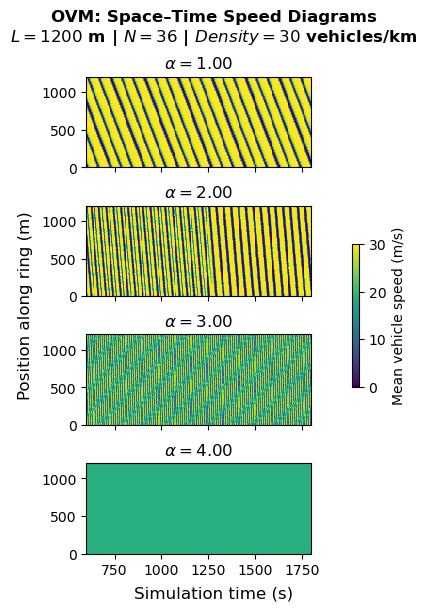

In [14]:
# Simulation parameters
length = 1200
n_vehicles = 30
seed = 501

alphas_selected = [1, 2, 3, 4]

time_start = 600
time_end = 1800

spatial_bin = 20
temporal_bin = 5

n_rows = len(alphas_selected)

fig, axes = plt.subplots(n_rows, 1, figsize=(4, 6), sharex=True, sharey=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, alpha in enumerate(alphas_selected):

    ax = axes[row]

    df = load_fcd_for_ovm(seed=seed, alpha=alpha, length=length, n_vehicles=n_vehicles)

    matrix = make_speed_matrix(df, length, spatial_bin=spatial_bin, temporal_bin=temporal_bin)

    im = ax.imshow(np.ma.masked_invalid(matrix.T), origin="lower", aspect="auto",
        extent=[time_start, time_end, 0, length],
        cmap=cmap, vmin=0, vmax=30, interpolation="nearest")

    ax.set_title(rf"$\alpha = {alpha:.2f}$", fontsize=12)

fig.supxlabel("Simulation time (s)", fontsize=12)
fig.supylabel("Position along ring (m)", fontsize=12)
fig.colorbar(im, ax=axes, label="Mean vehicle speed (m/s)", shrink=0.3, pad=0.1)

fig.suptitle(
    "OVM: Space–Time Speed Diagrams\n"
    r"$L = 1200$ m | $N = 36$ | $Density = 30$ vehicles/km",
    fontsize=12, fontweight="bold"
)

plt.show()

Instability only happens at V'(h) > a/2 from the formula:
1. At density 30, The effective gap is 26.33, hence V'(h) is 2.797. But since this is delta = 0.2, the ac = 3.59 
2. As the relaxation parameter increases the presence of stop-go-waves disappear